Using data directory: .


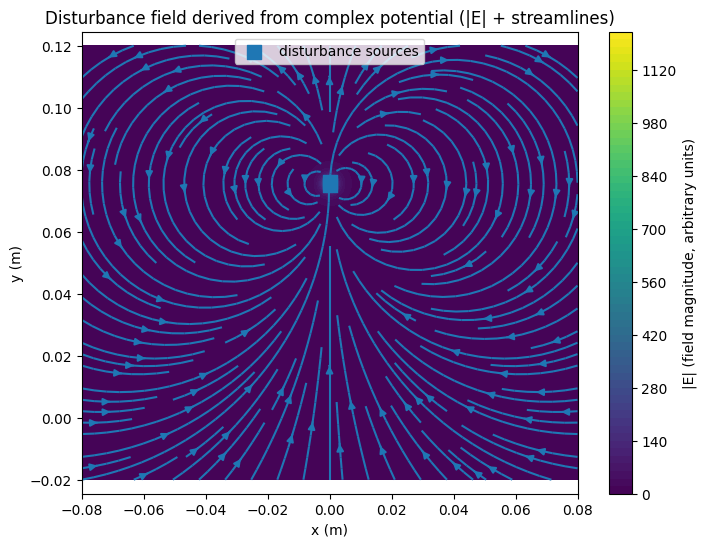

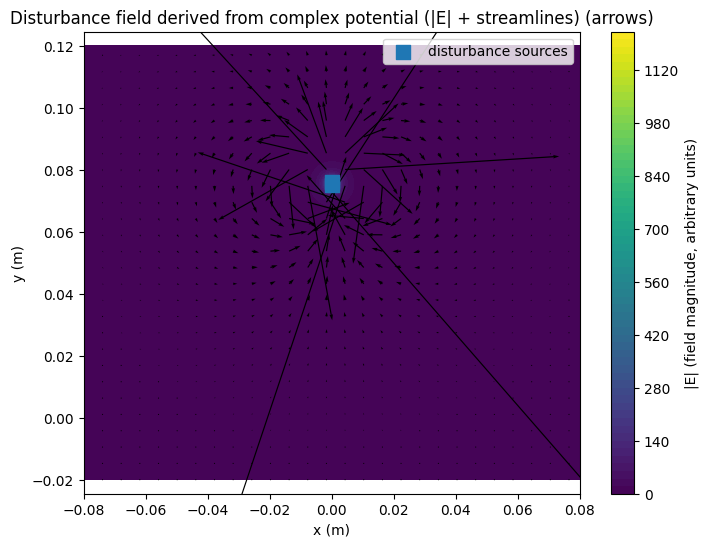

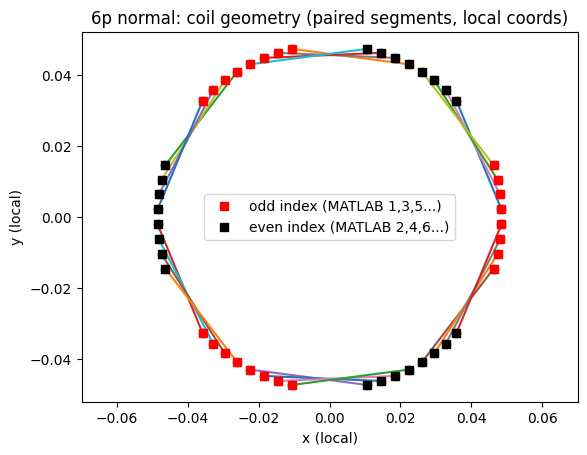

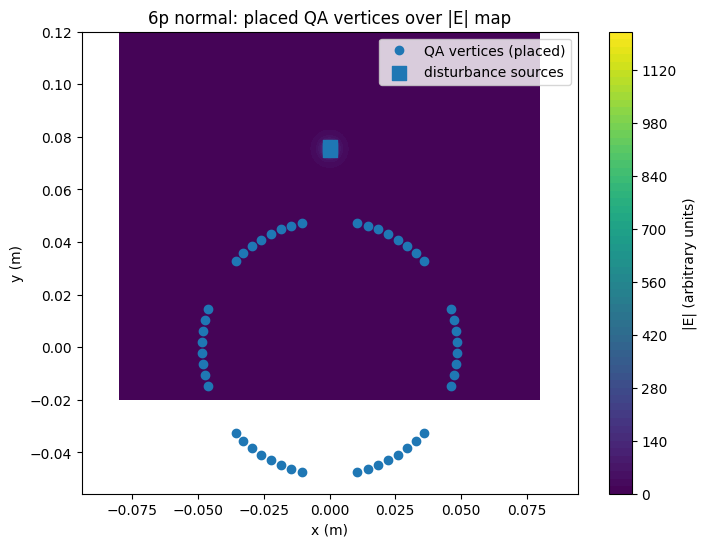

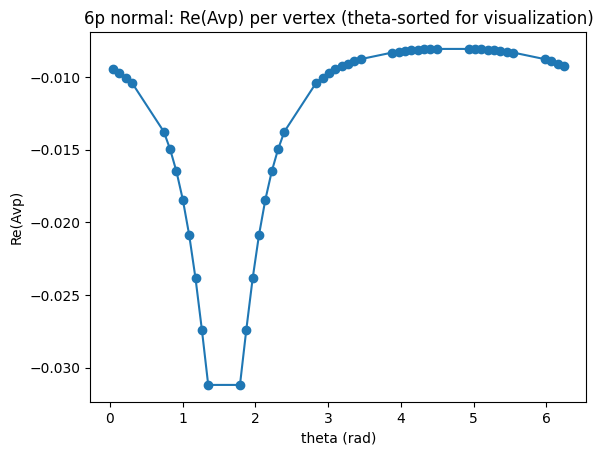

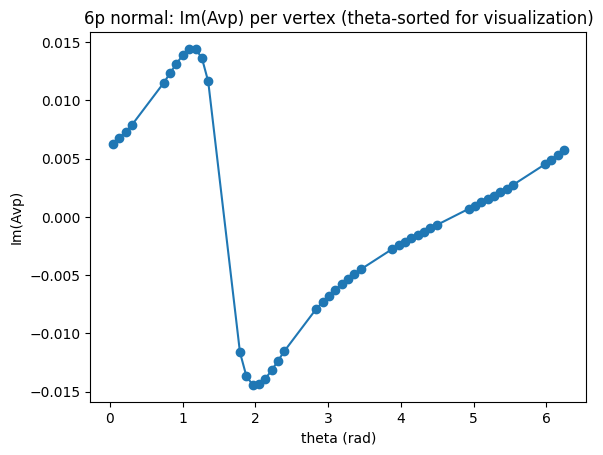

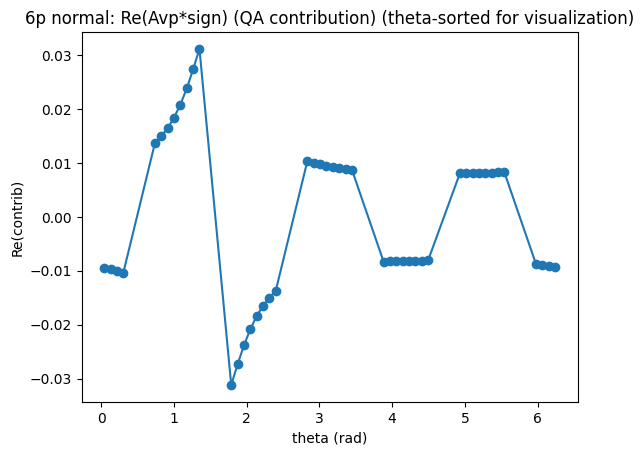

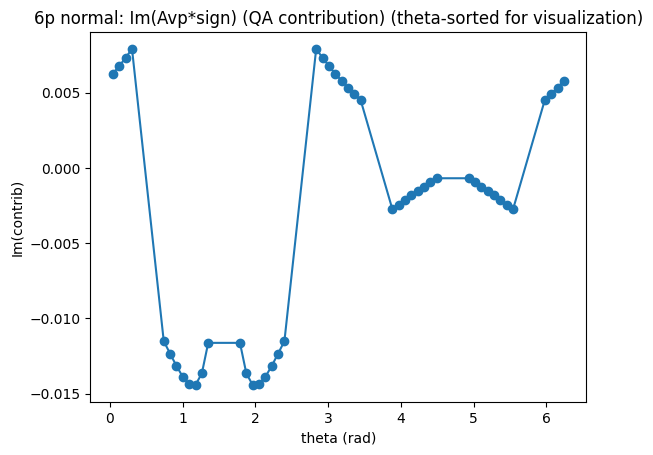

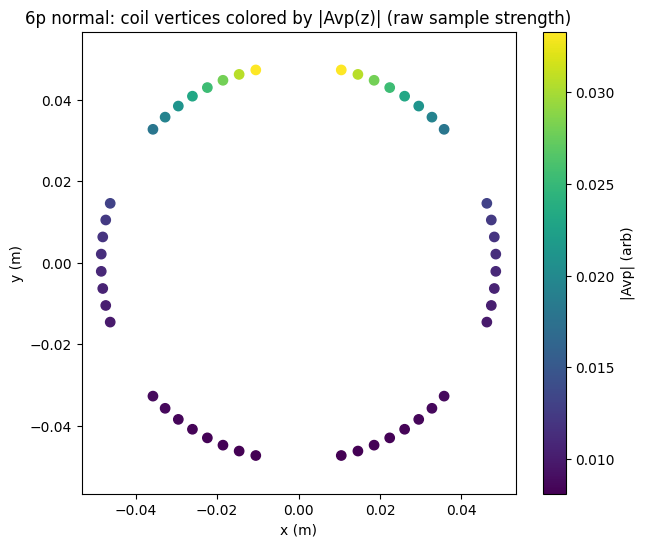

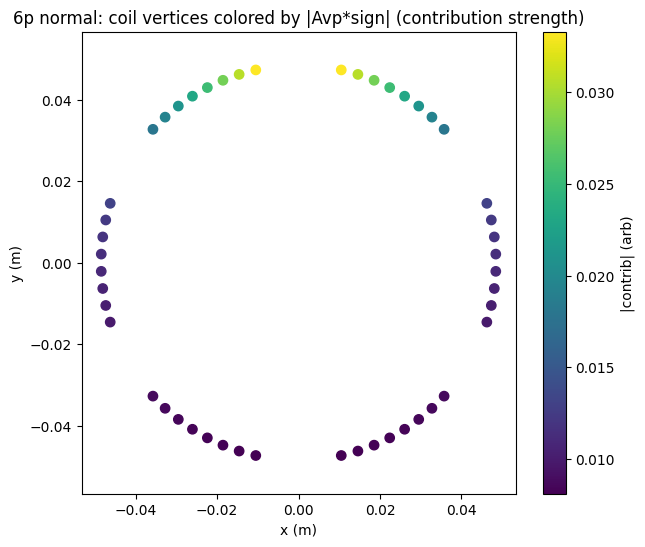


[6p normal] total = (2.042366276100438e-12-0.13963664860521496j)
[6p normal] |total| = 0.13963664860521496  phase(rad) = -1.5707963267802703


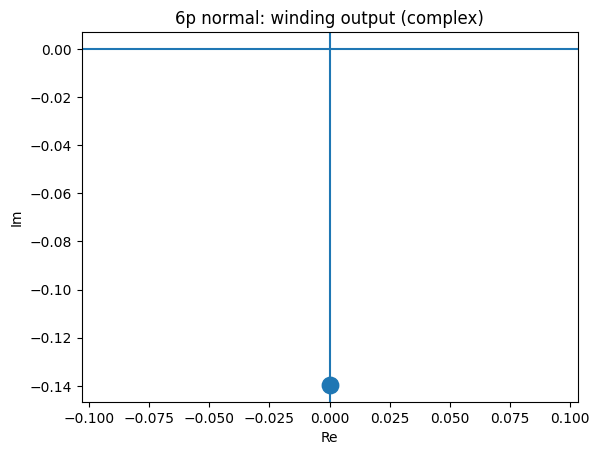

[6p normal] wrote flux_coilparam_MQXFA_test_6p_norm.dat


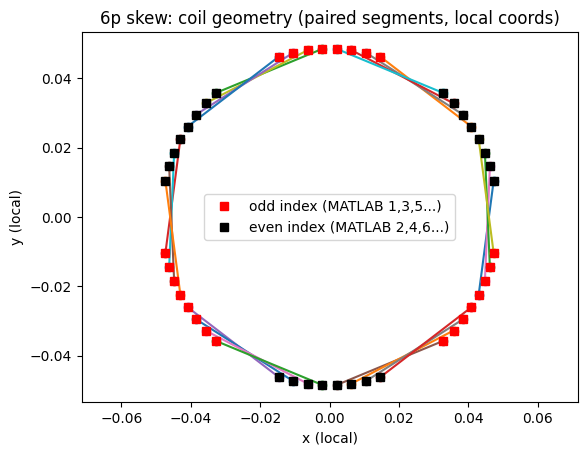

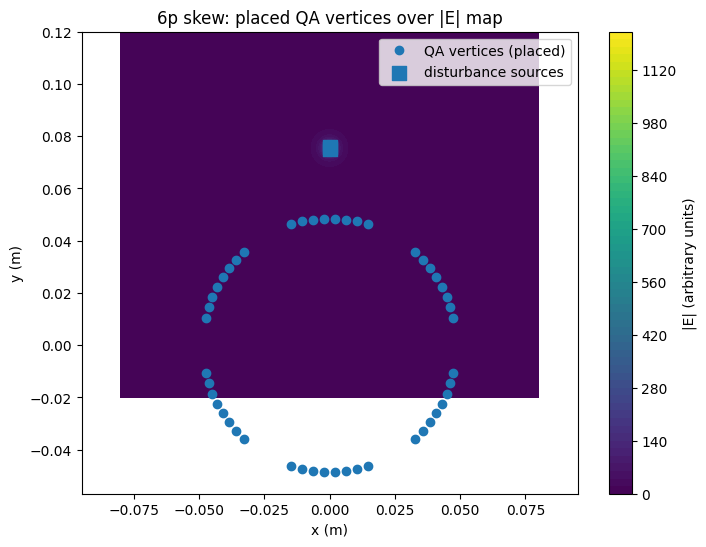

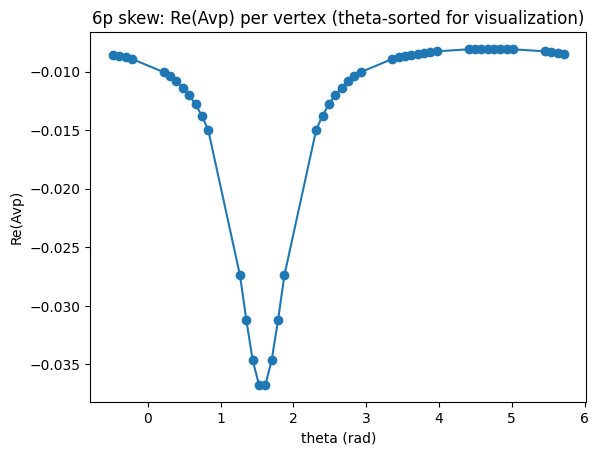

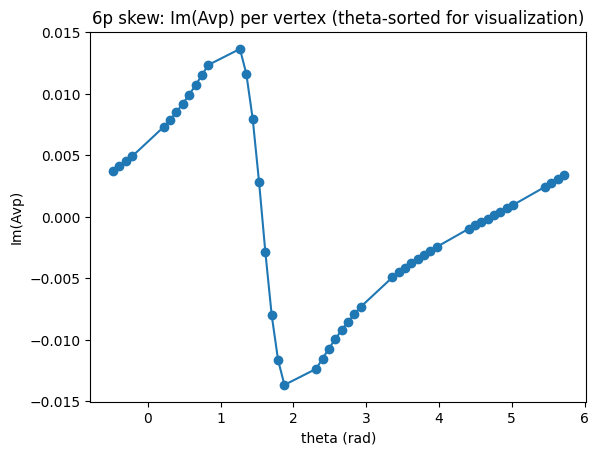

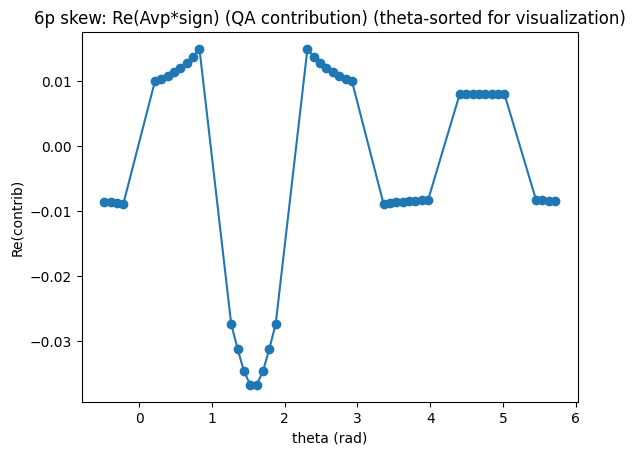

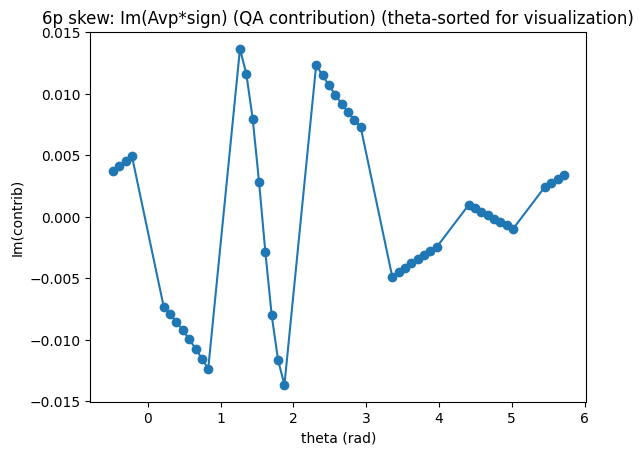

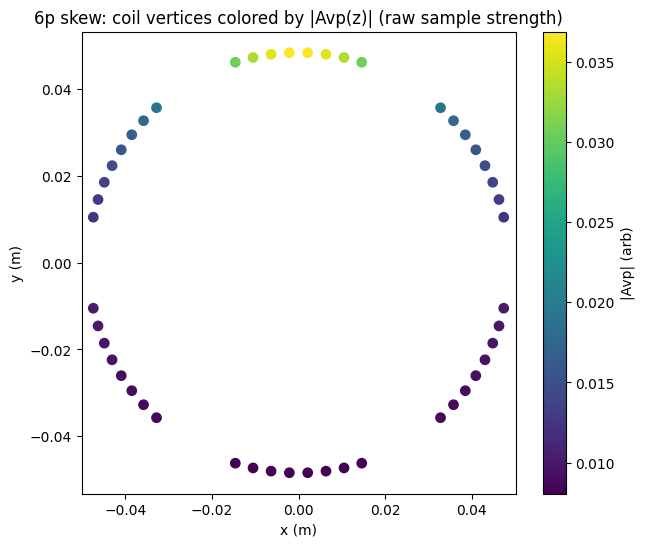

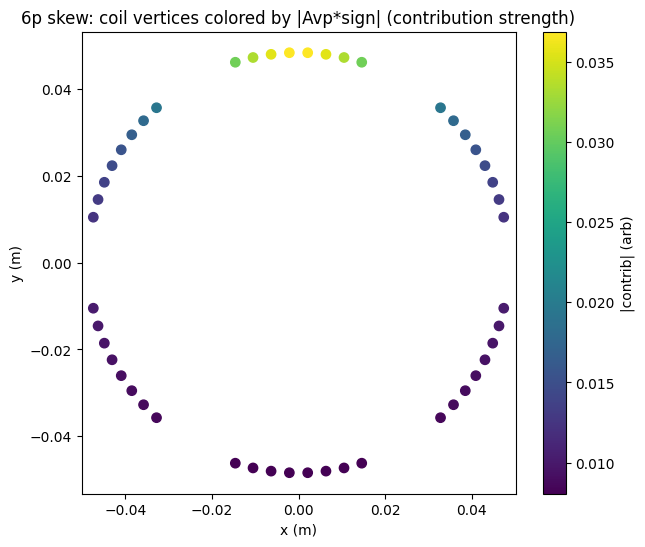


[6p skew] total = (-0.13965260248437517-2.084110661826344e-12j)
[6p skew] |total| = 0.13965260248437517  phase(rad) = -3.1415926535748695


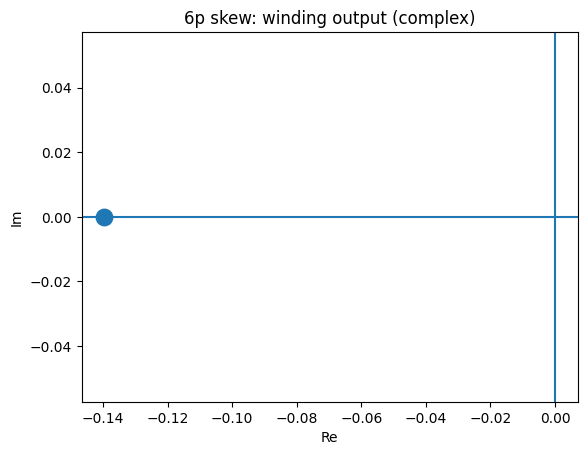

[6p skew] wrote flux_coilparam_MQXFA_test_6p_skew.dat


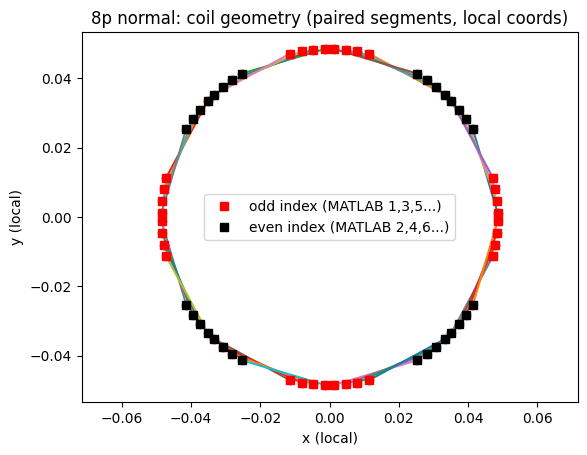

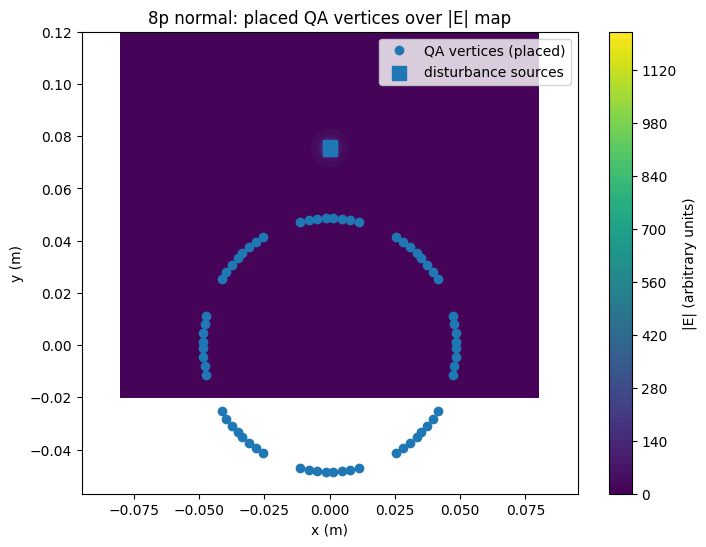

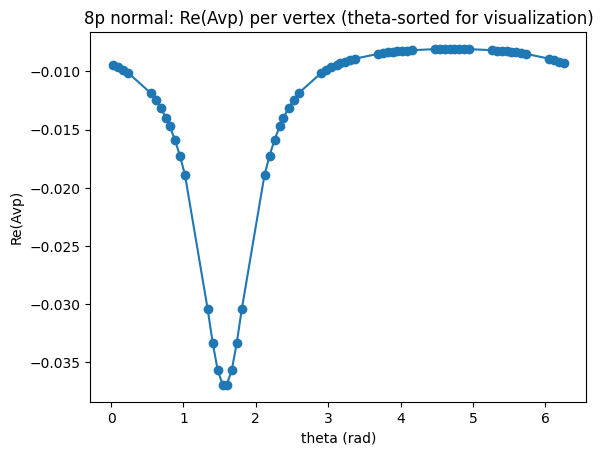

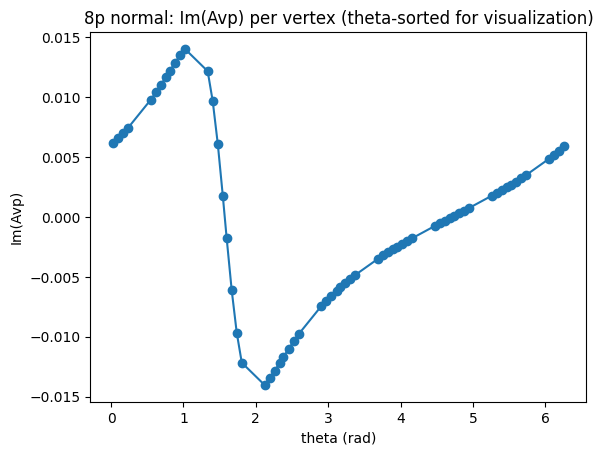

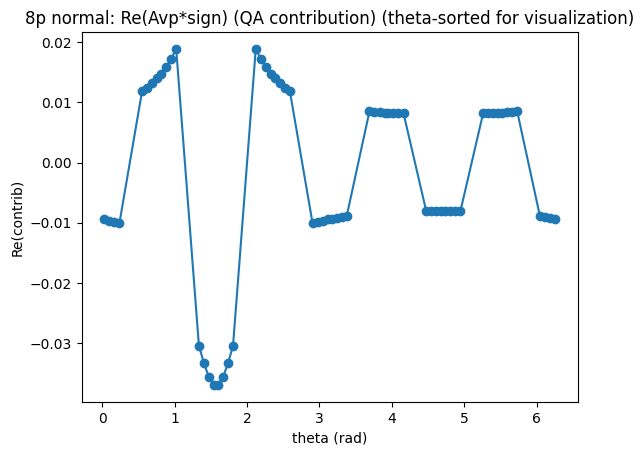

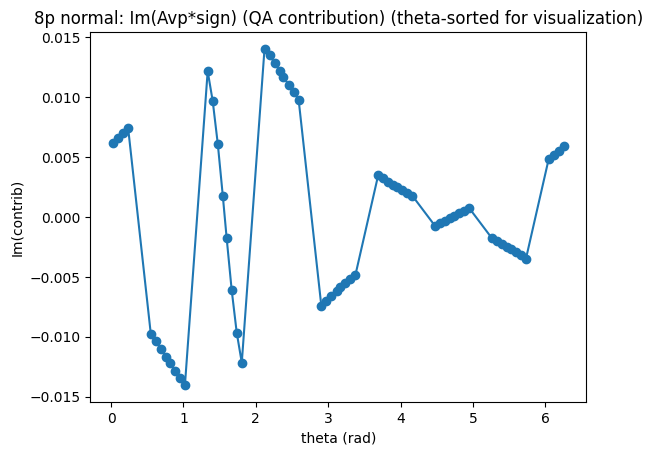

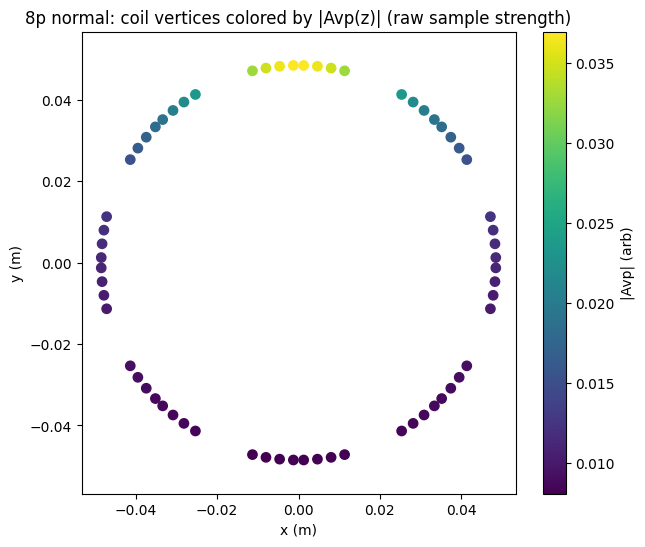

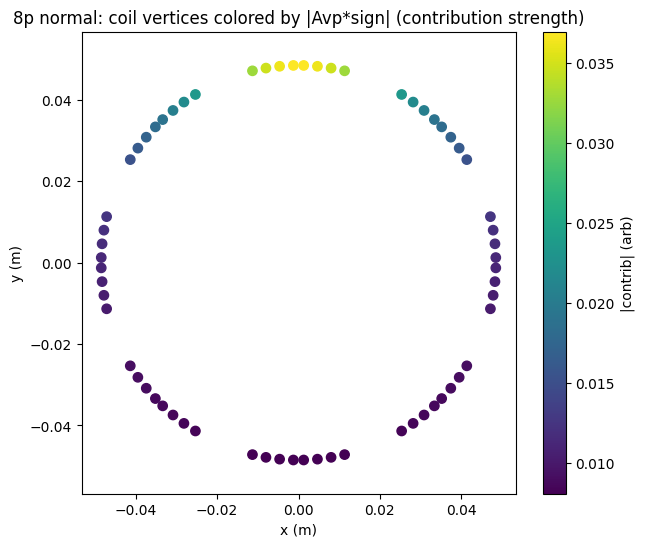


[8p normal] total = (-0.11901003999511817-2.3175905639050143e-12j)
[8p normal] |total| = 0.11901003999511817  phase(rad) = -3.1415926535703194


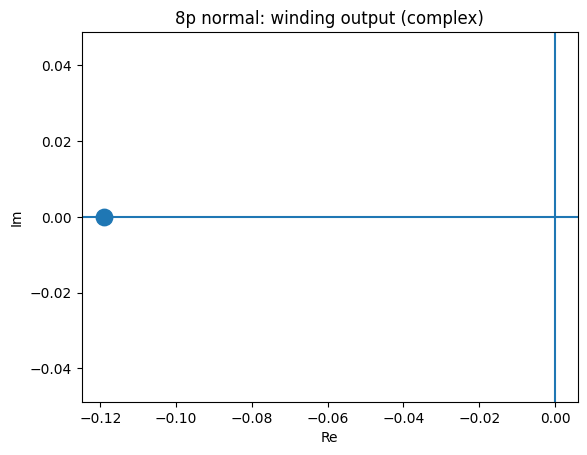

[8p normal] wrote flux_coilparam_MQXFA_test_8p_norm.dat


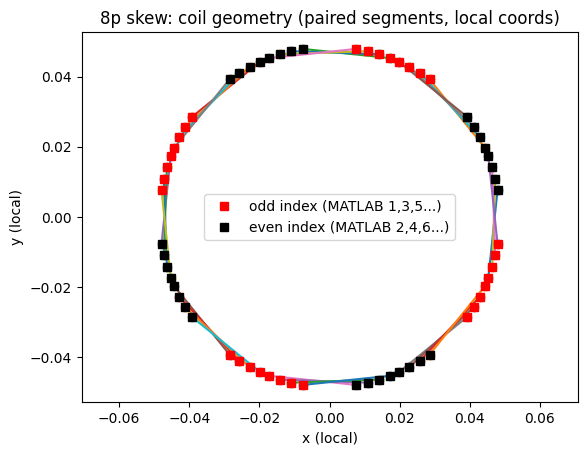

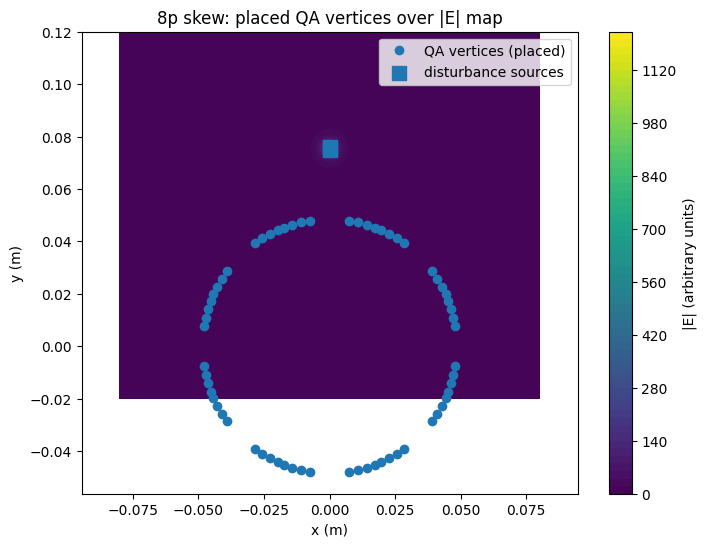

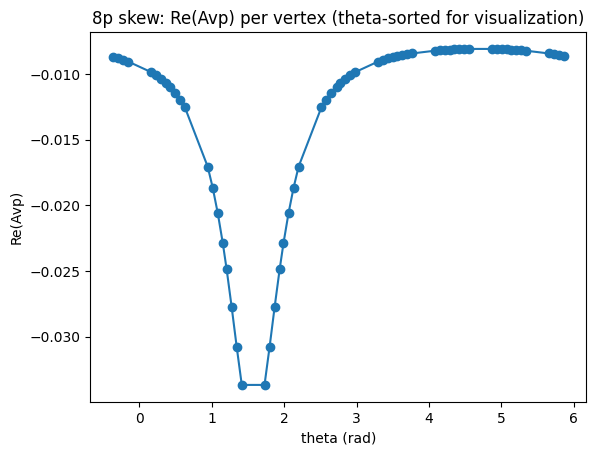

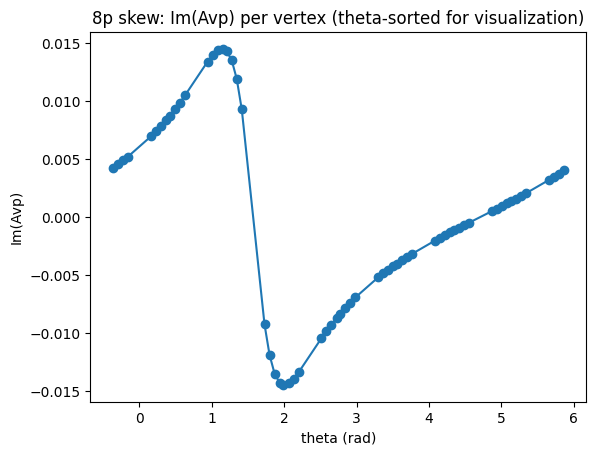

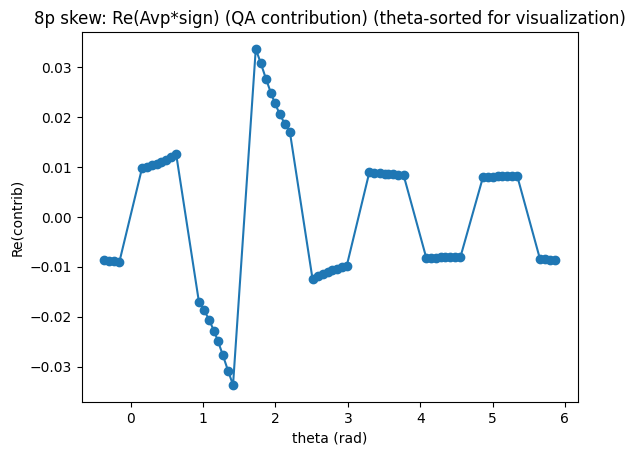

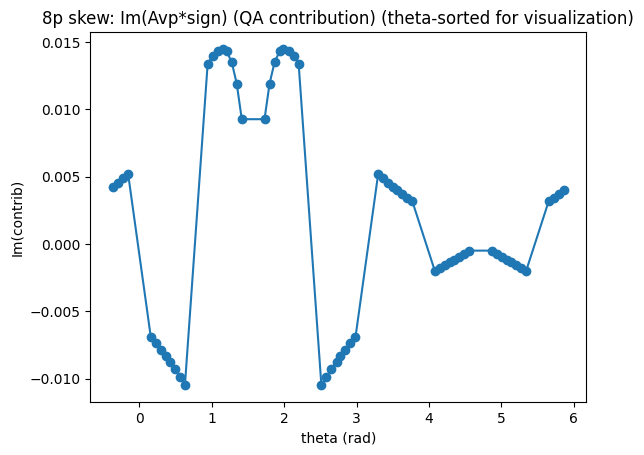

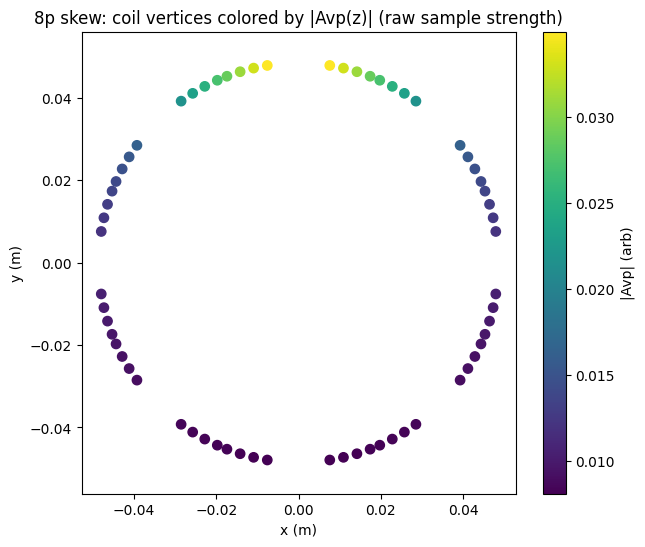

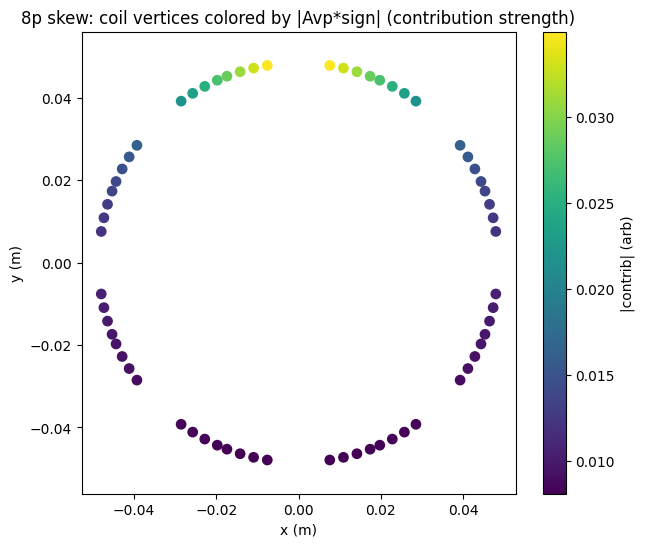


[8p skew] total = (-1.6275869541004795e-12+0.11900875505604114j)
[8p skew] |total| = 0.11900875505604114  phase(rad) = 1.5707963268085727


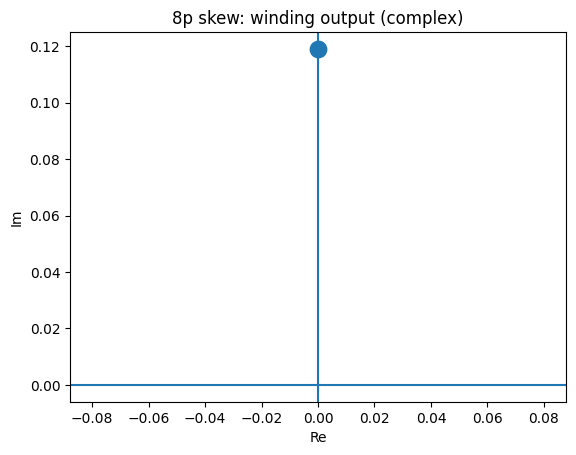

[8p skew] wrote flux_coilparam_MQXFA_test_8p_skew.dat

--- Harmonics / Localization (MATLAB-equivalent) ---
C6p  = (2.042366276100438e-12-0.13965260248437517j)  |C6p|= 0.13965260248437517  phase= -1.570796326780272
C8p  = (-0.11901003999511817-1.6275869541004795e-12j)  |C8p|= 0.11901003999511817  phase= -3.1415926535761174
qloc = (-7.180713874722953e-14+0.07570018872669557j)


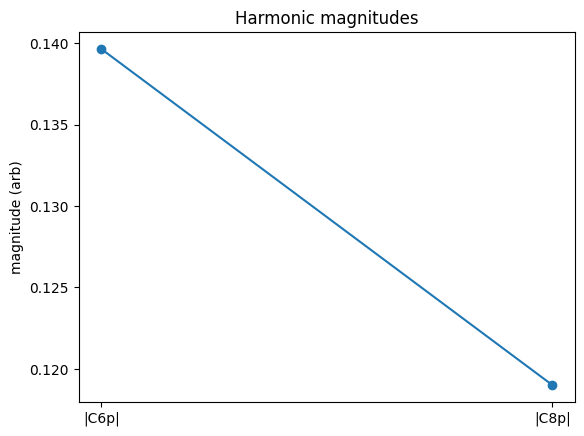

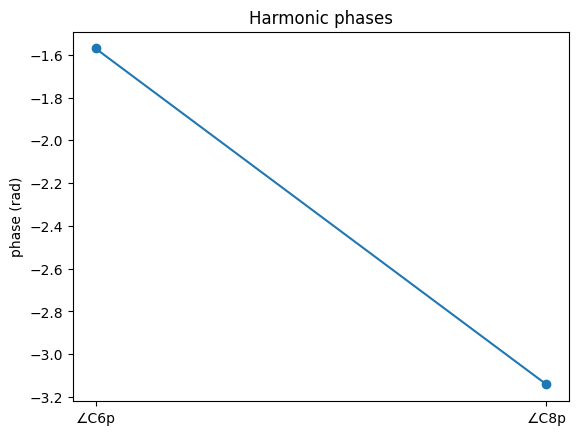

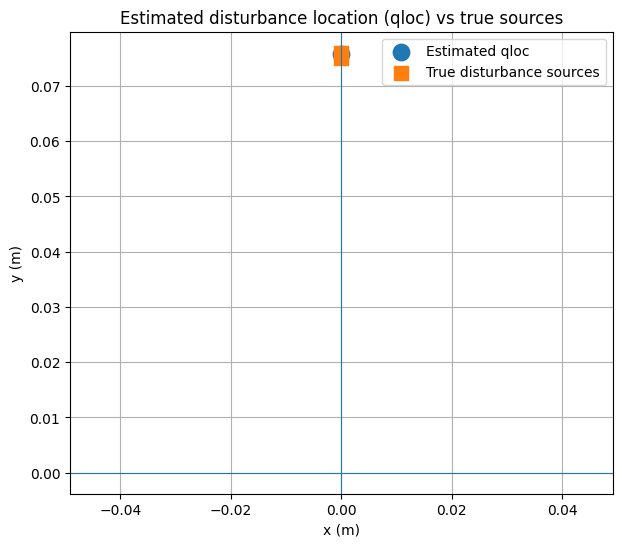

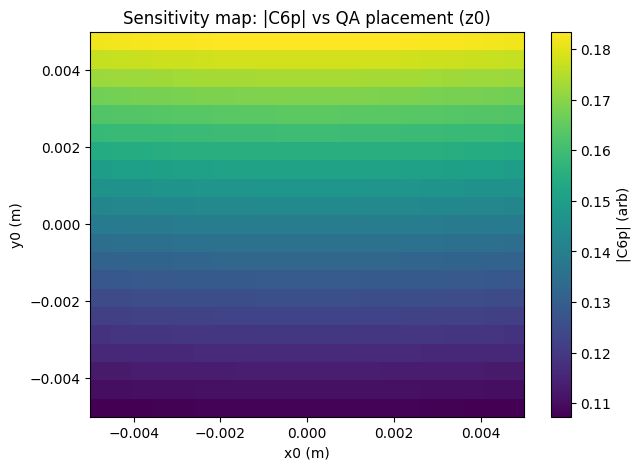

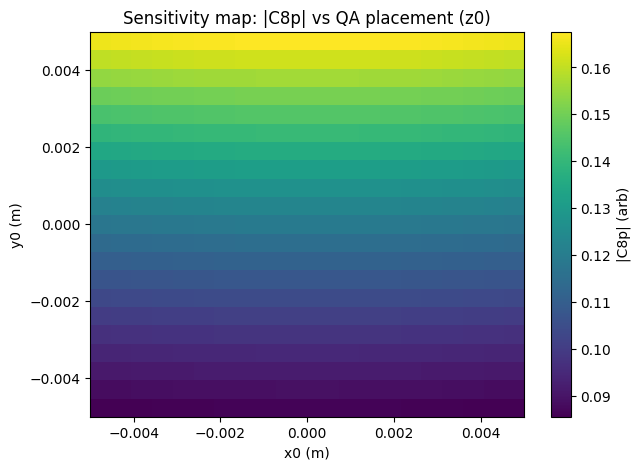

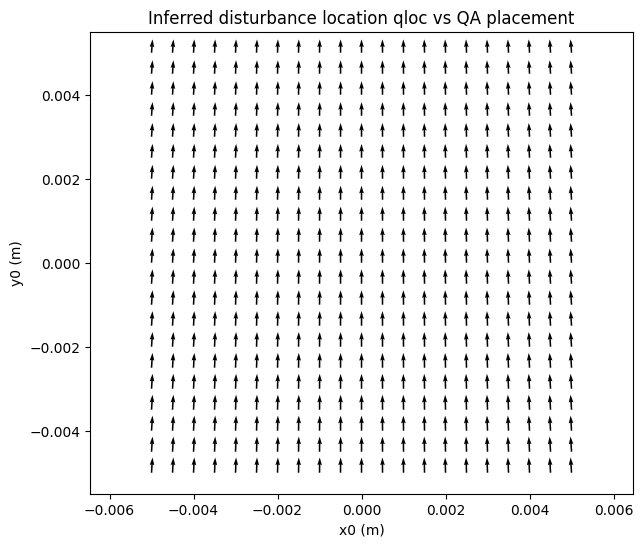

In [16]:
'''
What you get:
1) Disturbance (dipole-like) field map: |E| magnitude + streamlines + arrows using two infinite current lines (close together)
2) Overlay of each QA winding’s vertices (placed coil) on the field map
3) “What QA measures at each point”:
   - Avp(z_k) per vertex (complex)
   - signed contribution Avp(z_k)*sign_k per vertex (complex)
   - plots vs theta (sorted for visualization) AND colored points on the coil
4) Winding output per file: total complex response, magnitude & phase
5) C6p, C8p and inferred location qloc, plus qloc vs sources plot
'''

import os
import numpy as np
import matplotlib.pyplot as plt


# ----------------------------
# Configuration
# ----------------------------
DATA_DIR_CANDIDATES = [".", "/mnt/data"]

FILES = {
    "6p_norm": "coilparam_MQXFA_test_6p_norm.dat",
    "6p_skew": "coilparam_MQXFA_test_6p_skew.dat",
    "8p_norm": "coilparam_MQXFA_test_8p_norm.dat",
    "8p_skew": "coilparam_MQXFA_test_8p_skew.dat",
}

# Disturbance sources (MATLAB pointsZi)
pointsZi = np.array([0.0 + 0.075j, 0.0 + 0.076j], dtype=np.complex128)

# “Measurement radius” scaling used in MATLAB
measRadius = 0.048383

# Orientation angle (MATLAB uses 0)
orientAngle = 0.0  # radians

# QA placement (YOU CAN CHANGE THESE)
# z0 = x0 + i*y0 in meters (placement of antenna center)
QA_Z0 = 0.0 + 0.0j
QA_ROT = 0.0  # radians

# Field-map view limits (tune if you like)
FIELD_XLIM = (-0.08, 0.08)
FIELD_YLIM = (-0.02, 0.12)



def find_data_dir() -> str:
    for d in DATA_DIR_CANDIDATES:
        ok = True
        for fn in FILES.values():
            if not os.path.exists(os.path.join(d, fn)):
                ok = False
                break
        if ok:
            return d
    raise FileNotFoundError(
        "Could not find all coilparam files. Searched:\n" + "\n".join(DATA_DIR_CANDIDATES)
    )


def read_coilparam(path: str):
    """
    Parses lines like:
      length    nturns    R      Theta
      VERTEX RBUCK  1.0000000000e+00  1.00  4.8500000000e-02  7.4176493210e-01

    Returns arrays:
      lengths, nturns, R, theta, header
    """
    lengths, nturns, R, theta = [], [], [], []
    header = None
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if header is None:
                header = line
                continue
            parts = line.split()
            if len(parts) < 6:
                continue
            if parts[0].upper() != "VERTEX":
                continue
            try:
                L = float(parts[2])
                N = float(parts[3])
                r = float(parts[4])
                th = float(parts[5])
            except ValueError:
                continue
            lengths.append(L)
            nturns.append(N)
            R.append(r)
            theta.append(th)

    if len(R) == 0:
        raise ValueError(f"No coil vertices parsed from file: {path}")

    return (
        np.array(lengths, dtype=float),
        np.array(nturns, dtype=float),
        np.array(R, dtype=float),
        np.array(theta, dtype=float),
        header,
    )


def A_complex_potential(Z: np.ndarray, pointsZi_: np.ndarray) -> np.ndarray:
    """
    Same as MATLAB fluxCalc inner sum, but vectorized:
      Avp(z) = Σ_j [ ((-1)^j)*(-1) * log(z - p_j) ]  with MATLAB j starting at 1
    """
    Z = np.asarray(Z, dtype=np.complex128)
    pointsZi_ = np.asarray(pointsZi_, dtype=np.complex128).reshape(-1)
    A = np.zeros_like(Z, dtype=np.complex128)
    for j, p in enumerate(pointsZi_, start=1):
        A += ((-1) ** j) * (-1) * np.log(Z - p)
    return A


def dAdz(Z: np.ndarray, pointsZi_: np.ndarray) -> np.ndarray:
    """
    Derivative of complex potential:
      dA/dz = Σ_j [ ((-1)^j)*(-1) * 1/(z - p_j) ]
    """
    Z = np.asarray(Z, dtype=np.complex128)
    pointsZi_ = np.asarray(pointsZi_, dtype=np.complex128).reshape(-1)
    out = np.zeros_like(Z, dtype=np.complex128)
    for j, p in enumerate(pointsZi_, start=1):
        out += ((-1) ** j) * (-1) * (1.0 / (Z - p))
    return out


def alternating_signs(n: int) -> np.ndarray:
    """MATLAB alt_pm1: [+1, -1, +1, -1, ...] in FILE ORDER."""
    s = np.ones(n, dtype=float)
    s[1::2] *= -1.0
    return s


def place_vertices(R: np.ndarray, theta: np.ndarray, *, z0: complex, rotation: float) -> np.ndarray:
    """
    Place coil geometry in space:
      z_placed = z0 + exp(i*rotation) * (R * exp(i*theta))
    """
    z_local = R * np.exp(1j * theta)
    return z0 + np.exp(1j * rotation) * z_local


def qa_response_from_disturbance(R, theta, pointsZi_, *, z0=0.0+0.0j, rotation=0.0):
    """
    Returns:
      z_placed: complex vertex positions after placement
      Avp: A(z) per vertex (complex)
      signs: +/- pattern (file order)
      contrib: Avp*signs (complex)
      total: sum(contrib) (complex)   <-- this is the winding output
    """
    z_placed = place_vertices(R, theta, z0=z0, rotation=rotation)
    Avp = A_complex_potential(z_placed, pointsZi_)
    signs = alternating_signs(len(Avp))
    contrib = Avp * signs
    total = np.sum(contrib)
    return z_placed, Avp, signs, contrib, total
def winding_total_for_file(data_dir, key, z0, rotation):
    # read coil file
    _, _, R, theta, _ = read_coilparam(os.path.join(data_dir, FILES[key]))
    theta = theta - orientAngle
    _, _, _, _, total = qa_response_from_disturbance(
    R, theta, pointsZi, z0=z0, rotation=rotation
    )

    return total


def compute_all_totals_and_qloc(data_dir, z0, rotation):
    tot_6n = winding_total_for_file(data_dir, "6p_norm", z0, rotation)
    tot_6s = winding_total_for_file(data_dir, "6p_skew", z0, rotation)
    tot_8n = winding_total_for_file(data_dir, "8p_norm", z0, rotation)
    tot_8s = winding_total_for_file(data_dir, "8p_skew", z0, rotation)

    C6p = np.real(tot_6n) + 1j*np.real(tot_6s)
    C8p = np.real(tot_8n) + 1j*np.real(tot_8s)
    qloc = (4.0/3.0) * (C6p / C8p) * measRadius

    return {
        "tot_6n": tot_6n, "tot_6s": tot_6s, "tot_8n": tot_8n, "tot_8s": tot_8s,
        "C6p": C6p, "C8p": C8p, "qloc": qloc
    }


# Plotting
def plot_field_vector_map(pointsZi_, *, xlim, ylim, n=320, arrow_step=12, title="Disturbance field"):
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y

    deriv = dAdz(Z, pointsZi_)
    Ex = -np.real(deriv)
    Ey =  np.imag(deriv)
    Emag = np.sqrt(Ex**2 + Ey**2)

    # Mask close to singularities
    mask = np.zeros_like(Z, dtype=bool)
    for p in pointsZi_:
        mask |= np.abs(Z - p) < 5e-4
    Exm = np.ma.array(Ex, mask=mask)
    Eym = np.ma.array(Ey, mask=mask)
    Em  = np.ma.array(Emag, mask=mask)

    # Magnitude + streamlines
    plt.figure(figsize=(8, 6))
    plt.contourf(X, Y, Em, levels=70)
    plt.colorbar(label="|E| (field magnitude, arbitrary units)")
    plt.streamplot(X, Y, Exm.filled(0.0), Eym.filled(0.0), density=1.3)
    plt.scatter(np.real(pointsZi_), np.imag(pointsZi_), marker="s", s=90, label="disturbance sources")
    plt.title(title)
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.legend()
    plt.show()

    # Magnitude + arrows
    plt.figure(figsize=(8, 6))
    plt.contourf(X, Y, Em, levels=70)
    plt.colorbar(label="|E| (field magnitude, arbitrary units)")
    xs = X[::arrow_step, ::arrow_step]
    ys = Y[::arrow_step, ::arrow_step]
    exs = Exm[::arrow_step, ::arrow_step].filled(0.0)
    eys = Eym[::arrow_step, ::arrow_step].filled(0.0)
    plt.quiver(xs, ys, exs, eys, angles="xy")
    plt.scatter(np.real(pointsZi_), np.imag(pointsZi_), marker="s", s=90, label="disturbance sources")
    plt.title(title + " (arrows)")
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.legend()
    plt.show()


def overlay_coil_on_field(pointsZi_, z_coil, *, xlim, ylim, n=320, title="Coil sampling the disturbance"):
    """Overlay the placed coil vertices on a |E| magnitude map."""
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y

    deriv = dAdz(Z, pointsZi_)
    Ex = -np.real(deriv)
    Ey =  np.imag(deriv)
    Emag = np.sqrt(Ex**2 + Ey**2)

    mask = np.zeros_like(Z, dtype=bool)
    for p in pointsZi_:
        mask |= np.abs(Z - p) < 5e-4
    Em = np.ma.array(Emag, mask=mask)

    plt.figure(figsize=(8, 6))
    plt.contourf(X, Y, Em, levels=70)
    plt.colorbar(label="|E| (arbitrary units)")
    plt.plot(np.real(z_coil), np.imag(z_coil), "o", label="QA vertices (placed)")
    plt.scatter(np.real(pointsZi_), np.imag(pointsZi_), marker="s", s=90, label="disturbance sources")
    plt.title(title)
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.legend()
    plt.show()


def plot_coil_geometry_pairs(R, theta, title):
    x = R * np.cos(theta)
    y = R * np.sin(theta)
    plt.figure()
    for i in range(0, len(R) - 1, 2):
        plt.plot(x[i:i+2], y[i:i+2], "-o")
    plt.plot(x[0::2], y[0::2], "rs", label="odd index (MATLAB 1,3,5...)")
    plt.plot(x[1::2], y[1::2], "ks", label="even index (MATLAB 2,4,6...)")
    plt.title(title.replace("_", r"\_"))
    plt.axis("equal")
    plt.xlabel("x (local)")
    plt.ylabel("y (local)")
    plt.legend()
    plt.show()


def plot_vs_theta_sorted(theta, y, title, ylabel):
    idx = np.argsort(theta)
    plt.figure()
    plt.plot(theta[idx], y[idx], "-o")
    plt.title(title + " (theta-sorted for visualization)")
    plt.xlabel("theta (rad)")
    plt.ylabel(ylabel)
    plt.show()


def plot_complex_point(z, title):
    plt.figure()
    plt.scatter([np.real(z)], [np.imag(z)], s=140)
    plt.axhline(0); plt.axvline(0)
    plt.axis("equal")
    plt.title(title)
    plt.xlabel("Re")
    plt.ylabel("Im")
    plt.show()


def plot_colored_vertices(z_coil, values, title, cbar_label):
    """
    Shows “each point in the QA measured and the response”:
    coil vertices colored by |value| or Re(value).
    """
    plt.figure(figsize=(7, 6))
    sc = plt.scatter(np.real(z_coil), np.imag(z_coil), c=values, s=45)
    plt.colorbar(sc, label=cbar_label)
    plt.title(title)
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.show()

def run_winding(file_path, label, *, z0, rotation):
    L, N, R, theta, header = read_coilparam(file_path)

    # MATLAB: QA.data(:,4) = QA.data(:,4) - orientAngle
    theta = theta - orientAngle

    # Geometry pairing plot in local coordinates (file order pairing)
    plot_coil_geometry_pairs(R, theta, f"{label}: coil geometry (paired segments, local coords)")

    # Compute QA response at placed coil vertices
    z_placed, Avp, signs, contrib, total = qa_response_from_disturbance(
        R, theta, pointsZi, z0=z0, rotation=rotation
    )

    # Overlay coil on field magnitude map (so you SEE where it samples)
    overlay_coil_on_field(
        pointsZi, z_placed, xlim=FIELD_XLIM, ylim=FIELD_YLIM,
        title=f"{label}: placed QA vertices over |E| map"
    )

    # What each point “measures” (per vertex):
    # 1) Raw Avp along theta
    plot_vs_theta_sorted(theta, np.real(Avp), f"{label}: Re(Avp) per vertex", "Re(Avp)")
    plot_vs_theta_sorted(theta, np.imag(Avp), f"{label}: Im(Avp) per vertex", "Im(Avp)")

    # 2) Signed contribution Avp*signs (this is what gets summed)
    plot_vs_theta_sorted(theta, np.real(contrib), f"{label}: Re(Avp*sign) (QA contribution)", "Re(contrib)")
    plot_vs_theta_sorted(theta, np.imag(contrib), f"{label}: Im(Avp*sign) (QA contribution)", "Im(contrib)")

    # 3) Visual picture on the coil itself:
    plot_colored_vertices(
        z_placed, np.abs(Avp),
        title=f"{label}: coil vertices colored by |Avp(z)| (raw sample strength)",
        cbar_label="|Avp| (arb)"
    )
    plot_colored_vertices(
        z_placed, np.abs(contrib),
        title=f"{label}: coil vertices colored by |Avp*sign| (contribution strength)",
        cbar_label="|contrib| (arb)"
    )

    # Winding output (complex “channel”)
    mag = np.abs(total)
    ph = np.angle(total)
    print(f"\n[{label}] total = {total}")
    print(f"[{label}] |total| = {mag}  phase(rad) = {ph}")

    plot_complex_point(total, f"{label}: winding output (complex)")

    # Save MATLAB-like flux_ file (theta, real(contrib)) in FILE ORDER
    out = np.column_stack([theta, np.real(contrib)])
    out_name = "flux_" + os.path.basename(file_path)
    np.savetxt(out_name, out, delimiter=" ", fmt="%.10e")
    print(f"[{label}] wrote {out_name}")

    return total



def main():
    data_dir = find_data_dir()
    print("Using data directory:", data_dir)

    # 1) Disturbance field visualization (truth in space)
    plot_field_vector_map(
        pointsZi,
        xlim=FIELD_XLIM, ylim=FIELD_YLIM,
        title="Disturbance field derived from complex potential (|E| + streamlines)"
    )

    # 2) Run all four QA windings at the chosen placement
    tot_6n = run_winding(os.path.join(data_dir, FILES["6p_norm"]), "6p normal", z0=QA_Z0, rotation=QA_ROT)
    tot_6s = run_winding(os.path.join(data_dir, FILES["6p_skew"]), "6p skew",   z0=QA_Z0, rotation=QA_ROT)
    tot_8n = run_winding(os.path.join(data_dir, FILES["8p_norm"]), "8p normal", z0=QA_Z0, rotation=QA_ROT)
    tot_8s = run_winding(os.path.join(data_dir, FILES["8p_skew"]), "8p skew",   z0=QA_Z0, rotation=QA_ROT)

    # 3) MATLAB-style combination into complex harmonics
    C6p = np.real(tot_6n) + 1j * np.real(tot_6s)
    C8p = np.real(tot_8n) + 1j * np.real(tot_8s)
    qloc = (4.0 / 3.0) * (C6p / C8p) * measRadius

    print("\n--- Harmonics / Localization (MATLAB-equivalent) ---")
    print("C6p  =", C6p, " |C6p|=", np.abs(C6p), " phase=", np.angle(C6p))
    print("C8p  =", C8p, " |C8p|=", np.abs(C8p), " phase=", np.angle(C8p))
    print("qloc =", qloc)

    # 4) Summary plots
    plt.figure()
    plt.plot([0, 1], [np.abs(C6p), np.abs(C8p)], "-o")
    plt.xticks([0, 1], ["|C6p|", "|C8p|"])
    plt.ylabel("magnitude (arb)")
    plt.title("Harmonic magnitudes")
    plt.show()

    plt.figure()
    plt.plot([0, 1], [np.angle(C6p), np.angle(C8p)], "-o")
    plt.xticks([0, 1], ["∠C6p", "∠C8p"])
    plt.ylabel("phase (rad)")
    plt.title("Harmonic phases")
    plt.show()

    # 5) qloc vs sources in the complex plane
    plt.figure(figsize=(7, 6))
    plt.scatter(np.real(qloc), np.imag(qloc), s=140, marker="o", label="Estimated qloc")
    plt.scatter(np.real(pointsZi), np.imag(pointsZi), s=90, marker="s", label="True disturbance sources")
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.axis("equal")
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.title("Estimated disturbance location (qloc) vs true sources")
    plt.legend()
    plt.grid(True)
    plt.show()

    rotation = QA_ROT  # keep fixed for now
    
    # Sweep +/- 5 mm in x and y (edit as needed)
    xs = np.linspace(-0.005, 0.005, 21)
    ys = np.linspace(-0.005, 0.005, 21)
    
    mag6 = np.zeros((len(ys), len(xs)))
    mag8 = np.zeros((len(ys), len(xs)))
    qloc_x = np.zeros((len(ys), len(xs)))
    qloc_y = np.zeros((len(ys), len(xs)))
    
    for iy, y in enumerate(ys):
        for ix, x in enumerate(xs):
            z0 = x + 1j*y
            out = compute_all_totals_and_qloc(data_dir, z0=z0, rotation=rotation)
            mag6[iy, ix] = np.abs(out["C6p"])
            mag8[iy, ix] = np.abs(out["C8p"])
            qloc_x[iy, ix] = np.real(out["qloc"])
            qloc_y[iy, ix] = np.imag(out["qloc"])
    
    # Heatmap: |C6p|
    plt.figure(figsize=(7, 5))
    plt.imshow(mag6, origin="lower",
               extent=[xs[0], xs[-1], ys[0], ys[-1]], aspect="auto")
    plt.colorbar(label="|C6p| (arb)")
    plt.title("Sensitivity map: |C6p| vs QA placement (z0)")
    plt.xlabel("x0 (m)")
    plt.ylabel("y0 (m)")
    plt.show()
    
    # Heatmap: |C8p|
    plt.figure(figsize=(7, 5))
    plt.imshow(mag8, origin="lower",
               extent=[xs[0], xs[-1], ys[0], ys[-1]], aspect="auto")
    plt.colorbar(label="|C8p| (arb)")
    plt.title("Sensitivity map: |C8p| vs QA placement (z0)")
    plt.xlabel("x0 (m)")
    plt.ylabel("y0 (m)")
    plt.show()
    
    # Quiver: how qloc changes (vector field)
    plt.figure(figsize=(7, 6))
    Xg, Yg = np.meshgrid(xs, ys)
    plt.quiver(Xg, Yg, qloc_x, qloc_y, angles="xy")
    plt.title("Inferred disturbance location qloc vs QA placement")
    plt.xlabel("x0 (m)")
    plt.ylabel("y0 (m)")
    plt.axis("equal")
    plt.show()


    return qloc


if __name__ == "__main__":
    main()


In [23]:
import numpy as np

def simulate_and_estimate_qa_from_hts(
    *,
    # HTS model
    hts_positions_z: np.ndarray,          # shape (K,), complex positions of strands/filaments (m)
    hts_currents_t: np.ndarray,           # shape (T, K), current in each strand vs time (A) OR arbitrary units
    t: np.ndarray,                        # shape (T,), time array (s)

    # QA geometry (already loaded or loadable)
    windings: dict,                       # dict name -> (R, theta) in FILE ORDER
                                         # e.g. {"6p_norm": (R6n, th6n), ...}

    # QA placement
    z0: complex = 0.0 + 0.0j,             # antenna center offset (m)
    rotation: float = 0.0,                # antenna rotation (rad)

    # MATLAB-equivalent localization scaling
    measRadius: float = 0.048383,         # m
    qloc_scale: float = 4.0/3.0,          # factor used in your .m

    # Options
    use_deltaI: bool = True,              # if True, model disturbance as ΔI(t)=I(t)-I(0)
):
    """
    Forward model:
      HTS array (many filaments) -> complex potential A(z,t) -> QA flux-linkage proxy λ(t)
      λ_winding(t) = Σ_vertices  sign_i * A(z_i,t)
      voltage proxy v(t) = -dλ/dt  (units depend on your field kernel / calibration)

    Estimator:
      Use the same harmonic combination you already use:
        C6p(t) = Re(total_6p_norm(t)) + i*Re(total_6p_skew(t))
        C8p(t) = Re(total_8p_norm(t)) + i*Re(total_8p_skew(t))
        qloc(t) = qloc_scale * (C6p/C8p) * measRadius

    Returns:
      results dict with:
        totals[name] : complex array (T,)
        lambdas[name]: complex array (T,)  (same as totals; naming clarity)
        volts[name]  : complex array (T,)  (finite-difference -dλ/dt)
        C6p, C8p     : complex arrays (T,)
        qloc         : complex array (T,)
    """

    # -------------------------
    # Basic checks
    # -------------------------
    hts_positions_z = np.asarray(hts_positions_z, dtype=np.complex128).reshape(-1)
    t = np.asarray(t, dtype=float).reshape(-1)
    hts_currents_t = np.asarray(hts_currents_t, dtype=float)

    if hts_currents_t.ndim != 2:
        raise ValueError("hts_currents_t must be shape (T, K)")
    T, K = hts_currents_t.shape
    if len(t) != T:
        raise ValueError(f"t length {len(t)} must match hts_currents_t T={T}")
    if len(hts_positions_z) != K:
        raise ValueError(f"hts_positions_z length {len(hts_positions_z)} must match K={K}")

    # Disturbance as ΔI (often what matters in a quench onset)
    if use_deltaI:
        I0 = hts_currents_t[0:1, :]
        dI_t = hts_currents_t - I0
    else:
        dI_t = hts_currents_t

    # -------------------------
    # Helpers: same sign convention as your fluxCalc
    # A(z,t) = Σ_k [ dI_k(t) * log(z - z_k) ] (2D toy kernel)
    #
    # NOTE: This is a *toy* kernel for now; it matches the style of your existing log model.
    # To get absolute volts, you’d replace this kernel with a Biot–Savart-based scaling/calibration.
    # -------------------------
    def A_from_hts(Z: np.ndarray, dI_row: np.ndarray) -> np.ndarray:
        """
        Z: shape (N,), complex points (coil vertices)
        dI_row: shape (K,), disturbance current at time t
        returns A(Z) shape (N,)
        """
        # Broadcast: (N,1) - (1,K) -> (N,K)
        DZ = Z.reshape(-1, 1) - hts_positions_z.reshape(1, -1)
        return np.sum(dI_row.reshape(1, -1) * np.log(DZ), axis=1)

    def alternating_signs(n: int) -> np.ndarray:
        s = np.ones(n, dtype=float)
        s[1::2] *= -1.0
        return s

    def place_vertices(R: np.ndarray, theta: np.ndarray) -> np.ndarray:
        z_local = R * np.exp(1j * theta)
        return z0 + np.exp(1j * rotation) * z_local

    import numpy as np
import matplotlib.pyplot as plt

def place_vertices(R, theta, z0=0.0+0.0j, rotation=0.0):
    """z_placed = z0 + exp(i*rotation)*R*exp(i*theta)"""
    z_local = R * np.exp(1j * theta)
    return z0 + np.exp(1j * rotation) * z_local

def alternating_signs(n):
    s = np.ones(n, dtype=float)
    s[1::2] *= -1.0
    return s

def A_from_hts(Z, hts_positions_z, dI_row):
    """
    2D toy kernel (consistent with your existing log model):
      A(Z) = Σ_k dI_k * log(Z - z_k)
    """
    Z = np.asarray(Z, dtype=np.complex128).reshape(-1, 1)           # (N,1)
    zk = np.asarray(hts_positions_z, dtype=np.complex128).reshape(1, -1)  # (1,K)
    dI = np.asarray(dI_row, dtype=float).reshape(1, -1)             # (1,K)
    return np.sum(dI * np.log(Z - zk), axis=1)                      # (N,)

def dAdz_from_hts(Z, hts_positions_z, dI_row):
    """
    dA/dz = Σ_k dI_k / (Z - z_k)
    """
    Z = np.asarray(Z, dtype=np.complex128).reshape(-1, 1)
    zk = np.asarray(hts_positions_z, dtype=np.complex128).reshape(1, -1)
    dI = np.asarray(dI_row, dtype=float).reshape(1, -1)
    return np.sum(dI / (Z - zk), axis=1)

def field_map_from_hts(hts_positions_z, dI_row, xlim, ylim, n=300, mask_r=5e-4):
    """
    Returns grid X,Y and magnitude |E| where E derived from φ=Re(A), A built from HTS.
    Using analytic relation:
      dA/dz = φx - i φy  =>  Ex=-φx=-Re(dA/dz), Ey=-φy=Im(dA/dz)
    """
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)
    Z = (X + 1j * Y).reshape(-1)

    deriv = dAdz_from_hts(Z, hts_positions_z, dI_row)
    Ex = -np.real(deriv)
    Ey =  np.imag(deriv)
    Emag = np.sqrt(Ex**2 + Ey**2)

    # mask near singularities
    mask = np.zeros_like(Z, dtype=bool)
    for p in hts_positions_z:
        mask |= np.abs(Z - p) < mask_r

    Emag = np.ma.array(Emag, mask=mask).reshape(X.shape)
    Ex = np.ma.array(Ex, mask=mask).reshape(X.shape)
    Ey = np.ma.array(Ey, mask=mask).reshape(X.shape)

    return X, Y, Emag, Ex, Ey

def plot_qa_over_hts_field_with_voltage(
    *,
    t,                       # (T,)
    hts_positions_z,         # (K,)
    hts_currents_t,          # (T,K)  currents or disturbances
    winding_R_theta,         # (R,theta) for ONE winding to visualize
    z0=0.0+0.0j,
    rotation=0.0,
    xlim=(-0.08,0.08),
    ylim=(-0.02,0.12),
    time_index=None,         # which time slice to show (int). default: middle
    use_deltaI=True,
    title="QA over HTS disturbance field"
):
    """
    Produces:
      - 2D map of |E| from HTS disturbance at chosen time
      - QA vertices plotted on top, colored by |contribution| at each vertex
      - A voltage waveform (proxy) for this winding, with a marker at that time
    """

    t = np.asarray(t, dtype=float).reshape(-1)
    I = np.asarray(hts_currents_t, dtype=float)
    if use_deltaI:
        dI = I - I[0:1, :]
    else:
        dI = I

    T = len(t)
    if time_index is None:
        time_index = T // 2
    time_index = int(time_index)
    time_index = max(0, min(T-1, time_index))

    R, theta = winding_R_theta
    R = np.asarray(R, dtype=float).reshape(-1)
    theta = np.asarray(theta, dtype=float).reshape(-1)

    # placed QA vertices
    z_qa = place_vertices(R, theta, z0=z0, rotation=rotation)
    signs = alternating_signs(len(z_qa))

    # QA per-vertex “sample” and “contribution” at this time
    Avp = A_from_hts(z_qa, hts_positions_z, dI[time_index, :])
    contrib = Avp * signs
    lam = np.sum(contrib)  # flux-linkage proxy (complex)

    # voltage proxy for this winding: v = -dλ/dt
    lam_t = np.zeros(T, dtype=np.complex128)
    for it in range(T):
        Avp_it = A_from_hts(z_qa, hts_positions_z, dI[it, :])
        lam_t[it] = np.sum(Avp_it * signs)

    v_t = np.zeros(T, dtype=np.complex128)
    dt = np.diff(t)
    dlam = np.diff(lam_t)
    v_t[1:] = -(dlam / dt)
    v_t[0] = v_t[1]

    # Field map at this time
    X, Y, Emag, Ex, Ey = field_map_from_hts(
        hts_positions_z, dI[time_index, :], xlim=xlim, ylim=ylim, n=320
    )

    # ---- Plot: 2D field + QA overlay + vertex response coloring
    plt.figure(figsize=(10, 7))
    plt.contourf(X, Y, Emag, levels=70)
    plt.colorbar(label="|E| (field magnitude, arb)")

    # Overlay streamlines (optional but helpful)
    plt.streamplot(X, Y, Ex.filled(0.0), Ey.filled(0.0), density=1.1)

    # HTS positions
    plt.scatter(np.real(hts_positions_z), np.imag(hts_positions_z),
                marker="s", s=80, label="HTS strands/filaments")

    # QA vertices colored by |contribution|
    sc = plt.scatter(np.real(z_qa), np.imag(z_qa),
                     c=np.abs(contrib), s=45, label="QA vertices (colored by |contrib|)")
    cb = plt.colorbar(sc)
    cb.set_label("|QA per-vertex contribution| (arb)")

    plt.title(f"{title}\nTime = {t[time_index]:.6f} s  |λ|={np.abs(lam):.3e}  ∠λ={np.angle(lam):.3f} rad")
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.legend()
    plt.show()

    # ---- Plot: voltage waveform (proxy) with marker
    plt.figure(figsize=(10, 4))
    plt.plot(t, np.real(v_t), label="Re(v) = -d/dt Re(λ)")
    plt.plot(t, np.imag(v_t), label="Im(v) = -d/dt Im(λ)")
    plt.axvline(t[time_index], linestyle="--")
    plt.title("QA voltage measurement (proxy) for this winding (shape meaningful; absolute volts needs calibration)")
    plt.xlabel("time (s)")
    plt.ylabel("voltage proxy (arb/s)")
    plt.legend()
    plt.show()

    return {
        "z_qa": z_qa,
        "Avp": Avp,
        "contrib": contrib,
        "lambda_t": lam_t,
        "voltage_t": v_t,
        "time_index": time_index,
    }

    # -------------------------
    # Compute λ(t) for each winding
    # -------------------------
    totals = {}   # complex (T,)
    lambdas = {}  # alias
    volts = {}    # complex (T,)

    for name, (R, theta) in windings.items():
        R = np.asarray(R, dtype=float).reshape(-1)
        theta = np.asarray(theta, dtype=float).reshape(-1)

        # place vertices
        Z = place_vertices(R, theta)

        signs = alternating_signs(len(Z))

        lam = np.zeros(T, dtype=np.complex128)
        for it in range(T):
            Avals = A_from_hts(Z, dI_t[it, :])      # shape (N,)
            lam[it] = np.sum((Avals * signs))       # loop sum (FILE ORDER in your data arrays)

        totals[name] = lam
        lambdas[name] = lam

        # Voltage proxy: -dλ/dt (finite difference)
        v = np.zeros(T, dtype=np.complex128)
        dt = np.diff(t)
        dlam = np.diff(lam)
        v[1:] = -(dlam / dt)
        v[0] = v[1]  # simple fill
        volts[name] = v

    # -------------------------
    # Build harmonics and estimate qloc(t) like MATLAB
    # -------------------------
    def get(name):
        if name not in totals:
            raise KeyError(f"Missing winding '{name}' in windings dict.")
        return totals[name]

    tot_6n = get("6p_norm")
    tot_6s = get("6p_skew")
    tot_8n = get("8p_norm")
    tot_8s = get("8p_skew")

    C6p = np.real(tot_6n) + 1j * np.real(tot_6s)
    C8p = np.real(tot_8n) + 1j * np.real(tot_8s)

    # Avoid divide-by-zero explosions
    eps = 1e-30
    qloc = qloc_scale * (C6p / (C8p + eps)) * measRadius

    return {
        "totals": totals,
        "lambdas": lambdas,
        "volts": volts,
        "C6p": C6p,
        "C8p": C8p,
        "qloc": qloc,
        "t": t,
    }


In [24]:
data_dir = find_data_dir()
windings = {}
for k, fname in FILES.items():
    _, _, R, theta, _ = read_coilparam(os.path.join(data_dir, fname))
    theta = theta - orientAngle
    windings[k] = (R, theta)


In [25]:
# Example: 20 filaments on a small ring (toy HTS layout)
K = 20
r = 0.04
angles = np.linspace(0, 2*np.pi, K, endpoint=False)
hts_positions_z = r * np.exp(1j * angles)

# Time axis
t = np.linspace(0, 0.02, 2000)  # 20 ms

# Currents: start at 1, then one strand drops (quench) over time
I = np.ones((len(t), K))
tau = 0.002
I[:, 3] = 1.0 - (1.0 - np.exp(-t/tau))  # strand 3 decays from 1 -> ~0



In [26]:
out = simulate_and_estimate_qa_from_hts(
    hts_positions_z=hts_positions_z,
    hts_currents_t=I,
    t=t,
    windings=windings,
    z0=0.0+0.0j,
    rotation=0.0,
    measRadius=measRadius,
)


UnboundLocalError: local variable 'np' referenced before assignment

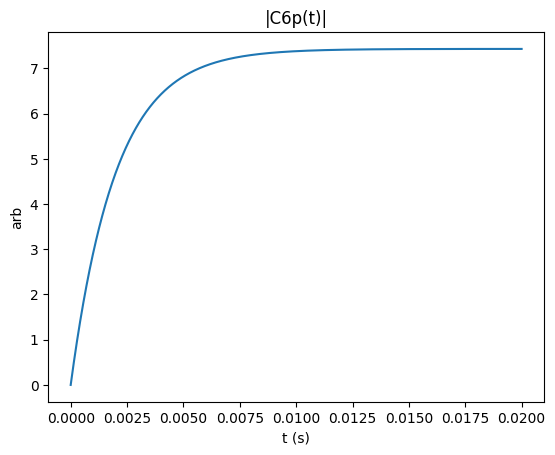

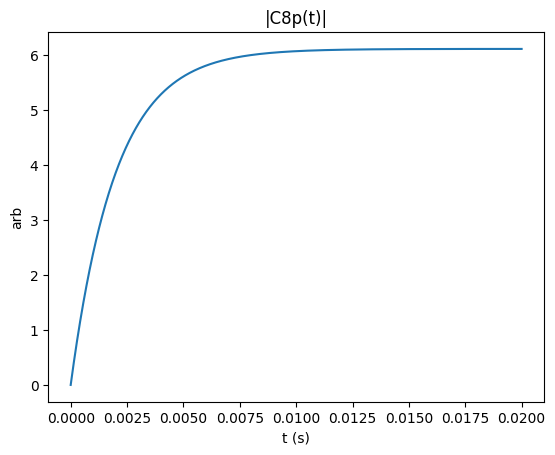

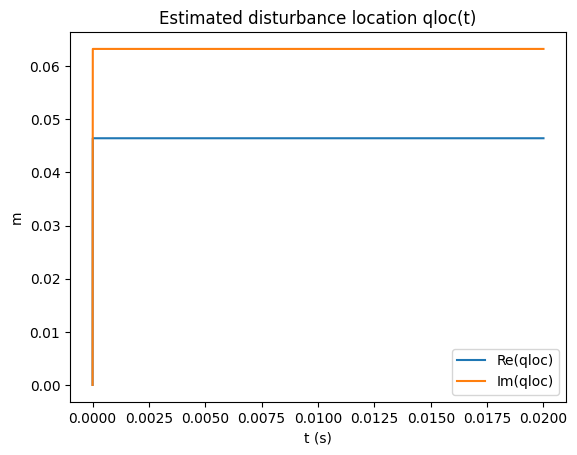

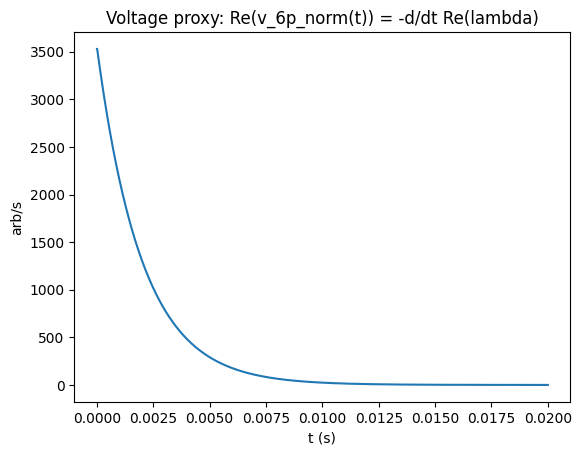

In [27]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(out["t"], np.abs(out["C6p"]))
plt.title("|C6p(t)|")
plt.xlabel("t (s)")
plt.ylabel("arb")
plt.show()

plt.figure()
plt.plot(out["t"], np.abs(out["C8p"]))
plt.title("|C8p(t)|")
plt.xlabel("t (s)")
plt.ylabel("arb")
plt.show()

plt.figure()
plt.plot(out["t"], np.real(out["qloc"]), label="Re(qloc)")
plt.plot(out["t"], np.imag(out["qloc"]), label="Im(qloc)")
plt.title("Estimated disturbance location qloc(t)")
plt.xlabel("t (s)")
plt.ylabel("m")
plt.legend()
plt.show()

# Voltage proxy for one channel (shape is meaningful; absolute volts needs calibration)
v6n = out["volts"]["6p_norm"]
plt.figure()
plt.plot(out["t"], np.real(v6n))
plt.title("Voltage proxy: Re(v_6p_norm(t)) = -d/dt Re(lambda)")
plt.xlabel("t (s)")
plt.ylabel("arb/s")
plt.show()


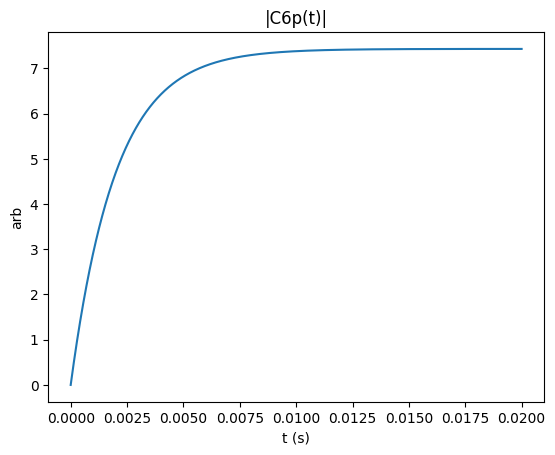

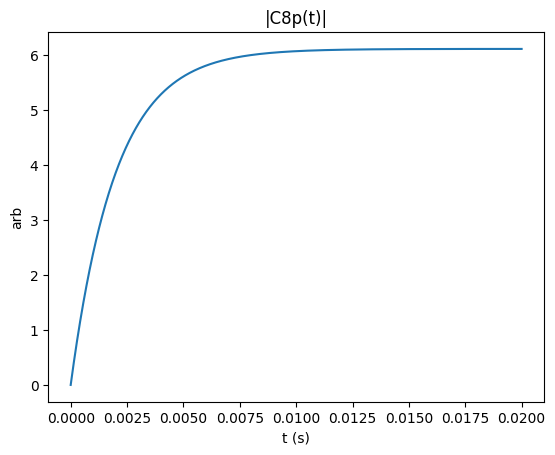

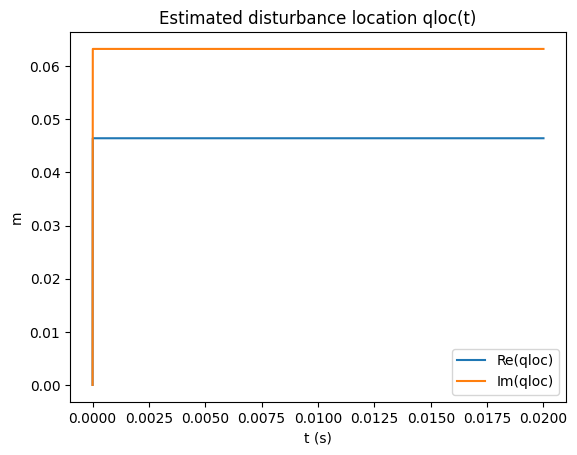

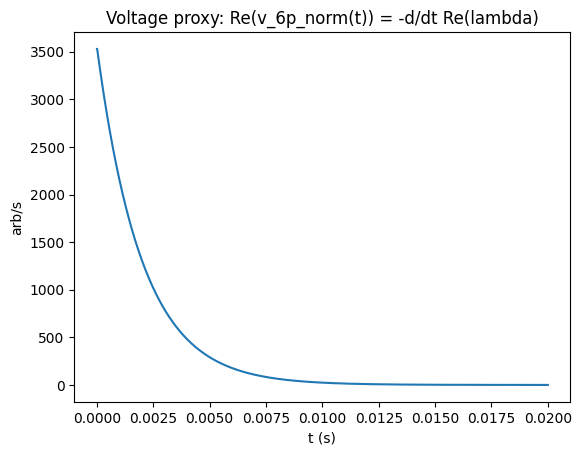

In [27]:
  b
plt.plot(out["t"], np.imag(out["qloc"]), label="Im(qloc)")
plt.title("Estimated disturbance location qloc(t)")
plt.xlabel("t (s)")
plt.ylabel("m")
plt.legend()
plt.show()

# Voltage proxy for one channel (shape is meaningful; absolute volts needs calibration)
v6n = out["volts"]["6p_norm"]
plt.figure()
plt.plot(out["t"], np.real(v6n))
plt.title("Voltage proxy: Re(v_6p_norm(t)) = -d/dt Re(lambda)")
plt.xlabel("t (s)")
plt.ylabel("arb/s")
plt.show()


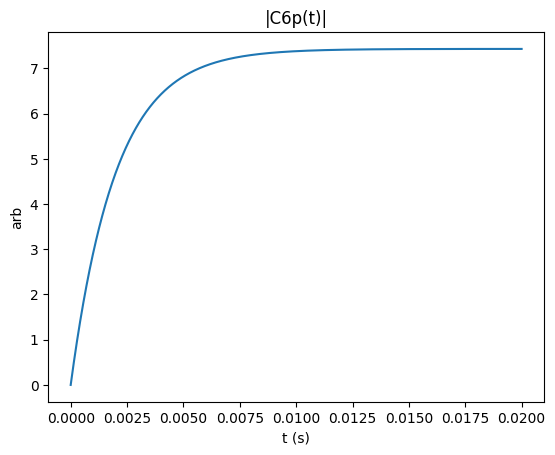

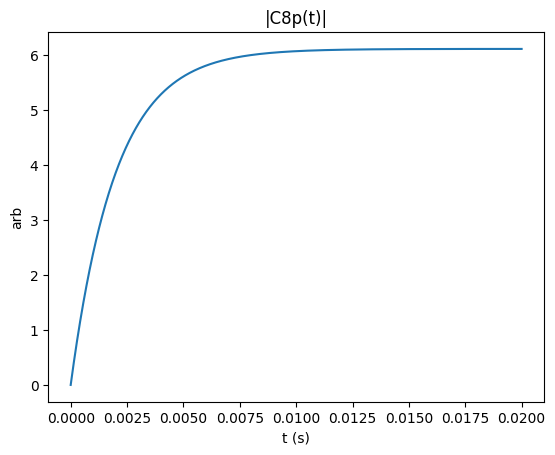

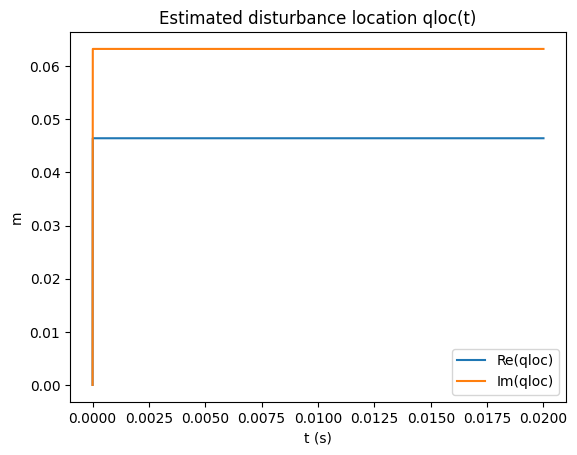

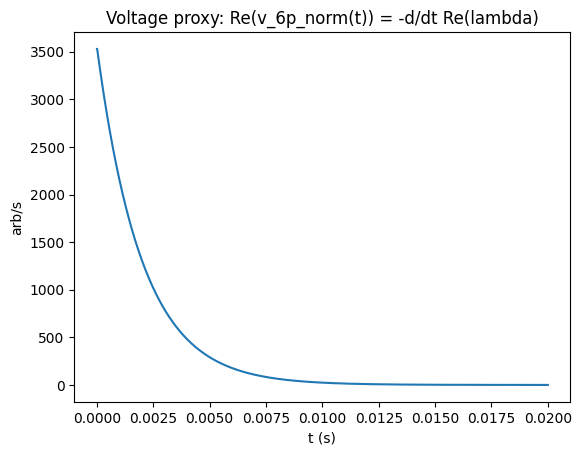

In [27]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(out["t"], np.abs(out["C6p"]))
plt.title("|C6p(t)|")
plt.xlabel("t (s)")
plt.ylabel("arb")
plt.show()

plt.figure()
plt.plot(out["t"], np.abs(out["C8p"]))
plt.title("|C8p(t)|")
plt.xlabel("t (s)")
plt.ylabel("arb")
plt.show()

plt.figure()
plt.plot(out["t"], np.real(out["qloc"]), label="Re(qloc)")
plt.plot(out["t"], np.imag(out["qloc"]), label="Im(qloc)")
plt.title("Estimated disturbance location qloc(t)")
plt.xlabel("t (s)")
plt.ylabel("m")
plt.legend()
plt.show()

# Voltage proxy for one channel (shape is meaningful; absolute volts needs calibration)
v6n = out["volts"]["6p_norm"]
plt.figure()
plt.plot(out["t"], np.real(v6n))
plt.title("Voltage proxy: Re(v_6p_norm(t)) = -d/dt Re(lambda)")
plt.xlabel("t (s)")
plt.ylabel("arb/s")
plt.show()


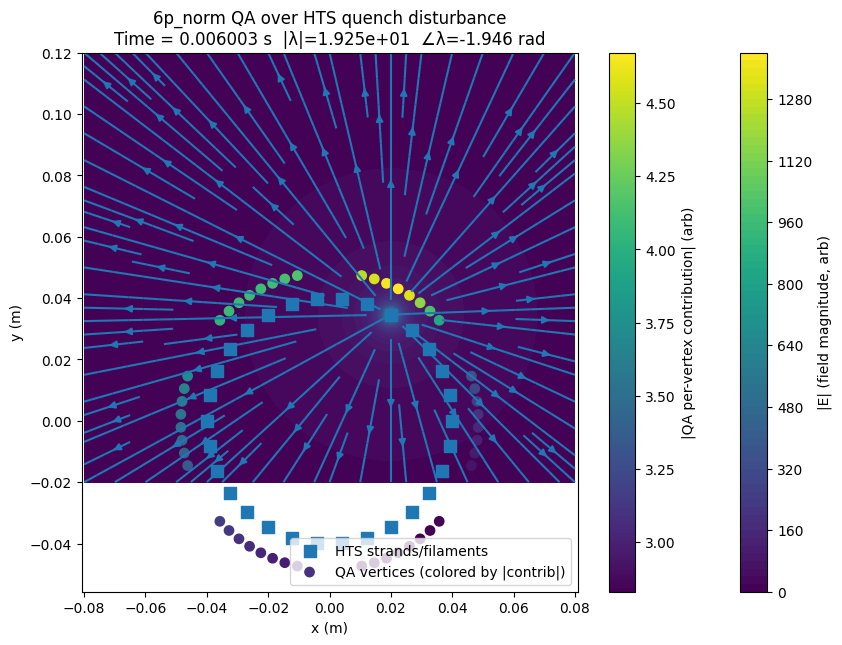

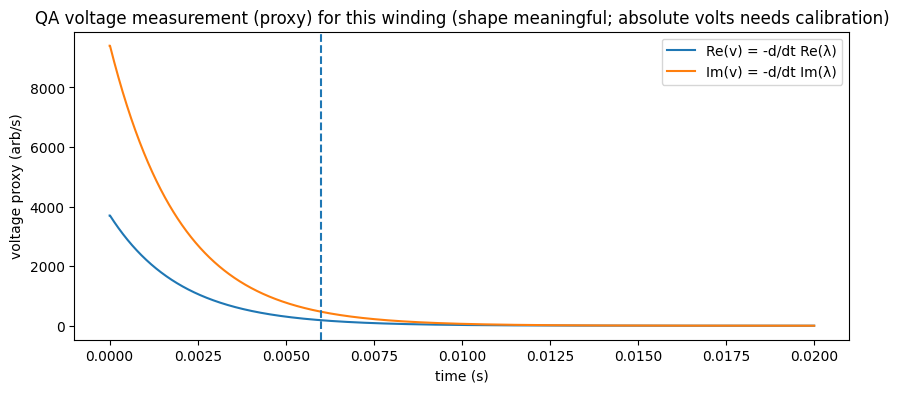

{'z_qa': array([ 0.04845384+0.00211554j,  0.03575795+0.03276613j,
        -0.01049732+0.04735036j,  0.02239481+0.04302003j,
        -0.02605903+0.04090449j, -0.04625527+0.01458423j,
        -0.03575795-0.03276613j, -0.04845384-0.00211554j,
        -0.02239481-0.04302003j,  0.01049732-0.04735036j,
         0.04625527-0.01458423j,  0.02605903-0.04090449j,
         0.04808508+0.00633052j,  0.03276613+0.03575795j,
        -0.01458423+0.04625527j,  0.01856015+0.04480816j,
        -0.02952493+0.03847764j, -0.04735036+0.01049732j,
        -0.03276613-0.03575795j, -0.04808508-0.00633052j,
        -0.01856015-0.04480816j,  0.01458423-0.04625527j,
         0.04735036-0.01049732j,  0.02952493-0.03847764j,
         0.04735036+0.01049732j,  0.02952493+0.03847764j,
        -0.01856015+0.04480816j,  0.01458423+0.04625527j,
        -0.03276613+0.03575795j, -0.04808508+0.00633052j,
        -0.02952493-0.03847764j, -0.04735036-0.01049732j,
        -0.01458423-0.04625527j,  0.01856015-0.04480816j,
      

In [28]:
data_dir = find_data_dir()

# Load ONE winding to visualize (6p_norm here)
_, _, R6n, th6n, _ = read_coilparam(os.path.join(data_dir, FILES["6p_norm"]))
th6n = th6n - orientAngle

# Example HTS array + quench evolution (replace with your real HTS model)
K = 30
r = 0.04
angles = np.linspace(0, 2*np.pi, K, endpoint=False)
hts_positions_z = r * np.exp(1j * angles)

t = np.linspace(0, 0.02, 2000)  # 20 ms
I = np.ones((len(t), K))
tau = 0.002
# one strand current decays (toy quench)
I[:, 5] = 1.0 - (1.0 - np.exp(-t/tau))

plot_qa_over_hts_field_with_voltage(
    t=t,
    hts_positions_z=hts_positions_z,
    hts_currents_t=I,
    winding_R_theta=(R6n, th6n),
    z0=0.0+0.0j,
    rotation=0.0,
    xlim=(-0.08, 0.08),
    ylim=(-0.02, 0.12),
    time_index=600,  # pick a time slice to visualize
    title="6p_norm QA over HTS quench disturbance"
)


In [29]:
import numpy as np

def make_rebco_tape_filaments(
    z_center: complex,
    width: float,
    thickness: float = 0.0,
    phi: float = 0.0,
    n_w: int = 41,
    n_t: int = 1,
):
    """
    Returns filament positions z_k (complex) representing a REBCO tape cross-section.

    width: tape width (m), e.g. 4e-3
    thickness: tape thickness (m), e.g. 100e-6 (often negligible in 2D)
    phi: rotation angle of tape width axis in the x-y plane
    n_w: number of filaments across width
    n_t: number of filaments across thickness (usually 1)
    """
    # coordinates in tape local frame: u across width, v across thickness
    u = np.linspace(-width/2, width/2, n_w)
    if n_t == 1 or thickness == 0.0:
        v = np.array([0.0])
    else:
        v = np.linspace(-thickness/2, thickness/2, n_t)

    U, V = np.meshgrid(u, v)
    pts = U.reshape(-1) + 1j * V.reshape(-1)

    # rotate tape in global plane
    pts_rot = pts * np.exp(1j * phi)

    # translate to center
    z = z_center + pts_rot
    return z


In [31]:
def tape_quench_currents_t(
    t: np.ndarray,
    filament_positions: np.ndarray,
    I_total: float,
    quench_center_u: float = 0.0,
    sigma_u0: float = 0.2e-3,
    sigma_u1: float = 1.0e-3,
    tau: float = 2e-3,
    drop_fraction: float = 0.8,
    phi: float = 0.0,
):
    """
    Build I_k(t) for filaments representing a tape.

    We assume filaments lie mostly along width axis u (in tape frame).
    Quench reduces current locally in u with a Gaussian notch whose width grows.

    - I_total: total current in tape (A)
    - drop_fraction: final fractional drop at the quench center
    - tau: timescale for growth
    """
    t = np.asarray(t, float)
    z = np.asarray(filament_positions, np.complex128)

    # convert filament positions to tape-local u coordinate (undo rotation)
    z_local = (z - np.mean(z)) * np.exp(-1j * phi)
    u = np.real(z_local)

    K = len(z)
    T = len(t)

    # baseline uniform distribution across filaments
    I0_per = I_total / K
    I = np.full((T, K), I0_per, dtype=float)

    # time-dependent notch
    # notch amplitude grows from 0 to drop_fraction
    a = (1.0 - np.exp(-t / tau))  # 0 -> 1
    # notch width grows from sigma_u0 -> sigma_u1
    sigma = sigma_u0 + (sigma_u1 - sigma_u0) * a

    for it in range(T):
        notch = np.exp(-0.5 * ((u - quench_center_u) / sigma[it])**2)
        notch = notch / (np.max(notch) + 1e-30)  # normalize
        I[it, :] = I0_per * (1.0 - drop_fraction * a[it] * notch)

    return I


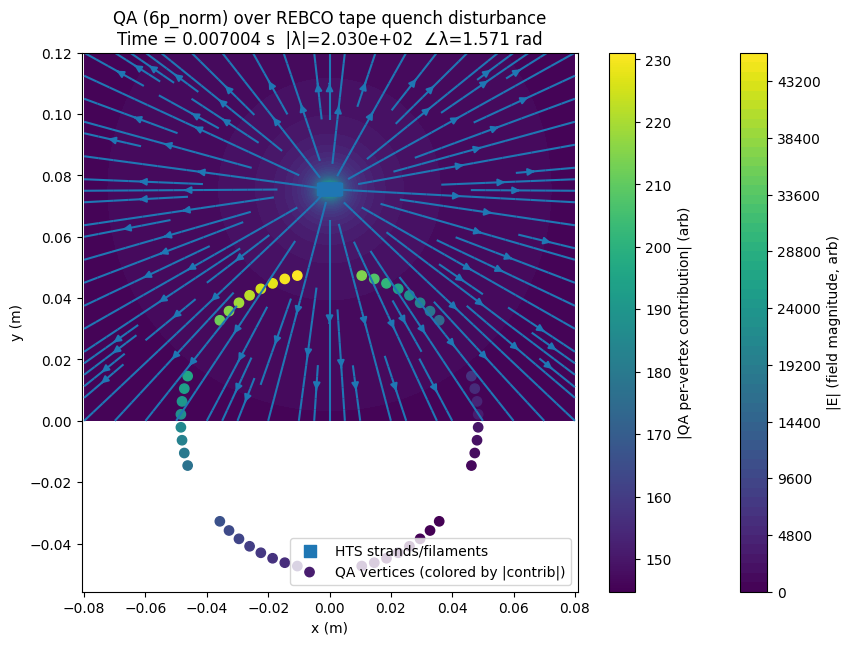

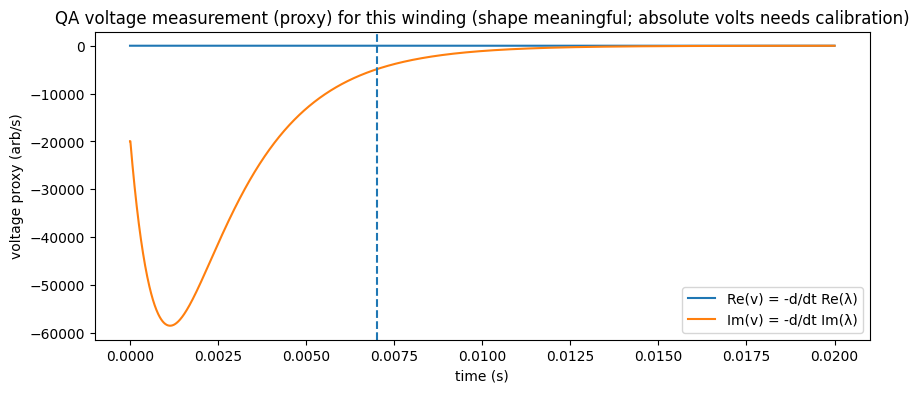

{'z_qa': array([ 0.04845384+0.00211554j,  0.03575795+0.03276613j,
        -0.01049732+0.04735036j,  0.02239481+0.04302003j,
        -0.02605903+0.04090449j, -0.04625527+0.01458423j,
        -0.03575795-0.03276613j, -0.04845384-0.00211554j,
        -0.02239481-0.04302003j,  0.01049732-0.04735036j,
         0.04625527-0.01458423j,  0.02605903-0.04090449j,
         0.04808508+0.00633052j,  0.03276613+0.03575795j,
        -0.01458423+0.04625527j,  0.01856015+0.04480816j,
        -0.02952493+0.03847764j, -0.04735036+0.01049732j,
        -0.03276613-0.03575795j, -0.04808508-0.00633052j,
        -0.01856015-0.04480816j,  0.01458423-0.04625527j,
         0.04735036-0.01049732j,  0.02952493-0.03847764j,
         0.04735036+0.01049732j,  0.02952493+0.03847764j,
        -0.01856015+0.04480816j,  0.01458423+0.04625527j,
        -0.03276613+0.03575795j, -0.04808508+0.00633052j,
        -0.02952493-0.03847764j, -0.04735036-0.01049732j,
        -0.01458423-0.04625527j,  0.01856015-0.04480816j,
      

In [32]:
# Time axis
t = np.linspace(0, 0.02, 2000)

# Build one tape (example: centered at x=0, y=0.0755 m)
tape_center = 0.0 + 0.0755j
tape_width = 4e-3           # 4 mm REBCO tape
tape_thickness = 0.0        # ignore thickness in 2D
tape_phi = 0.0              # tape flat along x

hts_positions_z = make_rebco_tape_filaments(
    z_center=tape_center,
    width=tape_width,
    thickness=tape_thickness,
    phi=tape_phi,
    n_w=61,
    n_t=1
)

# Currents over time with quench notch
I_total = 100.0  # A (example)
hts_currents_t = tape_quench_currents_t(
    t,
    hts_positions_z,
    I_total=I_total,
    quench_center_u=0.0e-3,
    sigma_u0=0.2e-3,
    sigma_u1=1.2e-3,
    tau=2e-3,
    drop_fraction=0.9,
    phi=tape_phi
)

# Load a QA winding (example 6p_norm)
data_dir = find_data_dir()
_, _, R6n, th6n, _ = read_coilparam(os.path.join(data_dir, FILES["6p_norm"]))
th6n = th6n - orientAngle

# Make the 2D plot + voltage measurement
plot_qa_over_hts_field_with_voltage(
    t=t,
    hts_positions_z=hts_positions_z,
    hts_currents_t=hts_currents_t,
    winding_R_theta=(R6n, th6n),
    z0=QA_Z0,
    rotation=QA_ROT,
    xlim=(-0.08, 0.08),
    ylim=(0.00, 0.12),
    time_index=700,
    use_deltaI=True,
    title="QA (6p_norm) over REBCO tape quench disturbance"
)
